# Approche 1 : features manuelles + modèles classiques

- On résume chaque session par **143 features** construites à la main (fréquences d'actions, d'écrans, de configurations, de chaînes, rythme, navigateur).
- On teste ensuite les modèles classiques, **un par cellule**, avec la même validation croisée, puis on les compare.
- La dernière cellule génère une soumission pour le modèle choisi.

Exploration des données et choix des valeurs aberrantes : `1_exploration.ipynb`.

## 1. Chargement des données

In [1]:
import os
import re
import time
import unicodedata
from collections import Counter

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # avertissements de police
MARQUEUR = re.compile(r"t\d+")

def lire_sessions(chemin, avec_label):
    """Une ligne par session : utilisateur (train seulement), navigateur, actions, durée (dernier marqueur tXX)."""
    lignes = []
    with open(chemin, encoding="utf-8") as f:
        for ligne in f:
            champs = ligne.rstrip("\n").split(",")
            util = champs.pop(0) if avec_label else None
            marqueurs = [int(e[1:]) for e in champs[1:] if MARQUEUR.fullmatch(e)]
            actions = [e for e in champs[1:] if not MARQUEUR.fullmatch(e)]
            lignes.append({"util": util, "navigateur": champs[0], "actions": actions,
                           "nb_actions": len(actions), "duree": marqueurs[-1] if marqueurs else 0})
    return pd.DataFrame(lignes)

train = lire_sessions("data/train.csv", avec_label=True)
test = lire_sessions("data/test.csv", avec_label=False)

# valeurs aberrantes (cf. 1_exploration) : on retire du train les sessions de moins de 10 actions, jamais du test
train = train[train["nb_actions"] >= 10].reset_index(drop=True)
utilisateurs = pd.Categorical(train["util"])
classes, y = utilisateurs.categories, utilisateurs.codes
print(len(train), "sessions d'entraînement,", len(test), "sessions de test,", len(classes), "utilisateurs")

3276 sessions d'entraînement, 324 sessions de test, 247 utilisateurs


## 2. Construction des features

Une action a la forme `Type(écran)<configuration>$chaîne$`, avec un `1` final si l'utilisateur est en modification.

In [2]:
P_ECRAN, P_CONF, P_CHAINE = re.compile(r"\((.*?)\)"), re.compile(r"<(.*?)>"), re.compile(r"\$(.*?)\$")

def type_action(action):
    """Texte avant l'écran, la configuration et la chaîne, sans le '1' final de modification."""
    t = re.split(r"[(<$]", action)[0]
    return t[:-1] if t.endswith("1") else t

def contexte(action):
    """(écran, configuration, chaîne) de l'action, None si absent."""
    return tuple(m.group(1) if (m := p.search(action)) else None for p in (P_ECRAN, P_CONF, P_CHAINE))

train["actions"][1][:4]

["Création d'un écran(infologic.core.gui.controllers.BlankController)",
 "Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow)",
 'Sélection d’un onglet(infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm)<TELEM_MINIMAL>',
 "Exécution d'un bouton"]

Pour chaque session :
- **fréquence relative** (compte ÷ nombre d'actions) des 35 types d'action et des 50 écrans, 20 configurations et 30 chaînes les plus courants du train ;
- 4 statistiques : `nb_actions_log`, `actions_par_s`, `part_modification`, `nb_types_distincts` ;
- le navigateur en one-hot.

Vocabulaires fixés sur le train uniquement, réutilisés tels quels pour le test.

In [3]:
TOP_K = {"ecran": 50, "conf": 20, "chaine": 30}

def comptes_session(actions):
    c = {"type": Counter(type_action(a) for a in actions), "ecran": Counter(), "conf": Counter(), "chaine": Counter()}
    for a in actions:
        for famille, valeur in zip(("ecran", "conf", "chaine"), contexte(a)):
            if valeur is not None:
                c[famille][valeur] += 1
    return c

comptes_train = [comptes_session(a) for a in train["actions"]]
comptes_test = [comptes_session(a) for a in test["actions"]]

# tous les types d'action, top-K pour les autres familles
vocab = {}
for famille, k in {"type": None, **TOP_K}.items():
    total = Counter()
    for c in comptes_train:
        total.update(c[famille])
    vocab[famille] = [v for v, _ in total.most_common(k)]
NAVIGATEURS = sorted(train["navigateur"].unique())

def features_manuelles(df, comptes):
    lignes = []
    for actions, nb, duree, nav, c in zip(df["actions"], df["nb_actions"], df["duree"], df["navigateur"], comptes):
        n = max(nb, 1)  # évite la division par 0 pour une session vide du test
        f = {"nb_actions_log": np.log1p(nb), "actions_par_s": nb / duree if duree else 0.0,
             "part_modification": sum(a.endswith("1") for a in actions) / n, "nb_types_distincts": len(c["type"])}
        for famille, valeurs in vocab.items():
            f.update({f"{famille}_{v}": c[famille][v] / n for v in valeurs})
        f.update({f"nav_{x}": int(nav == x) for x in NAVIGATEURS})
        lignes.append(f)
    return pd.DataFrame(lignes)

X_train, X_test = features_manuelles(train, comptes_train), features_manuelles(test, comptes_test)
print(X_train.shape, X_test.shape)

(3276, 143) (324, 143)


**Pourquoi des fréquences relatives ?** Un compte brut mélange l'utilisateur et la longueur de la session : diviser par le nombre d'actions rend comparables une session courte et une longue du même utilisateur.

## 3. Inspection des features

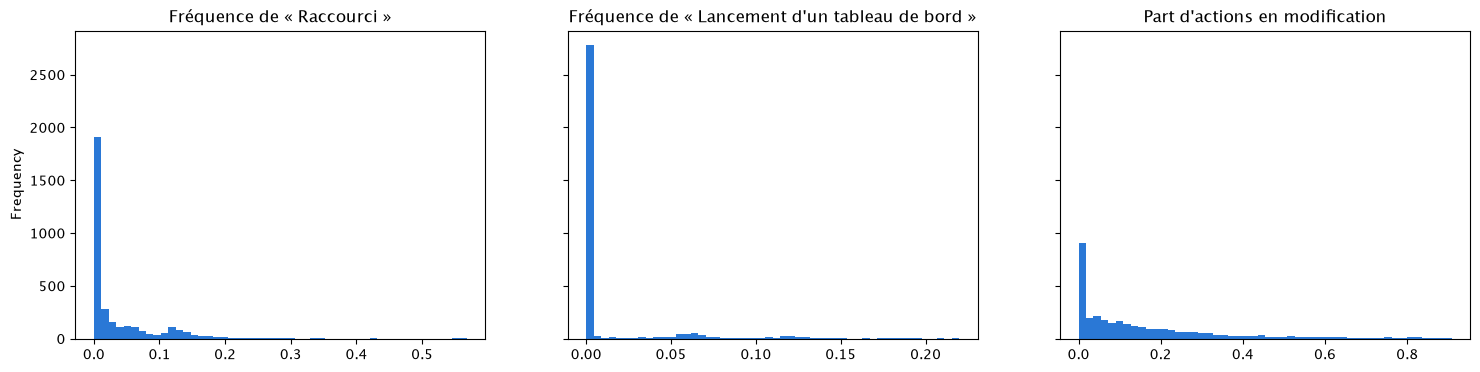

In [4]:
fig, axs = plt.subplots(ncols=3, sharey=True, figsize=(18, 4))
for ax, (col, titre) in zip(axs, [("type_Raccourci", "Fréquence de « Raccourci »"),
                                  ("type_Lancement d'un tableau de bord", "Fréquence de « Lancement d'un tableau de bord »"),
                                  ("part_modification", "Part d'actions en modification")]):
    X_train[col].plot.hist(bins=50, ax=ax, title=titre, color="#2a78d6")
plt.show()

**Observations**
- « Raccourci » : nulle pour environ 1900 sessions sur 3276, et fréquente chez une partie des utilisateurs (bosse vers 0,1).
- « Lancement d'un tableau de bord » : usage de niche, propre à quelques profils.
- `part_modification` : la plupart des sessions consultent plus qu'elles ne modifient.
- Ce sont les types moyens ou rares qui différencient les utilisateurs.

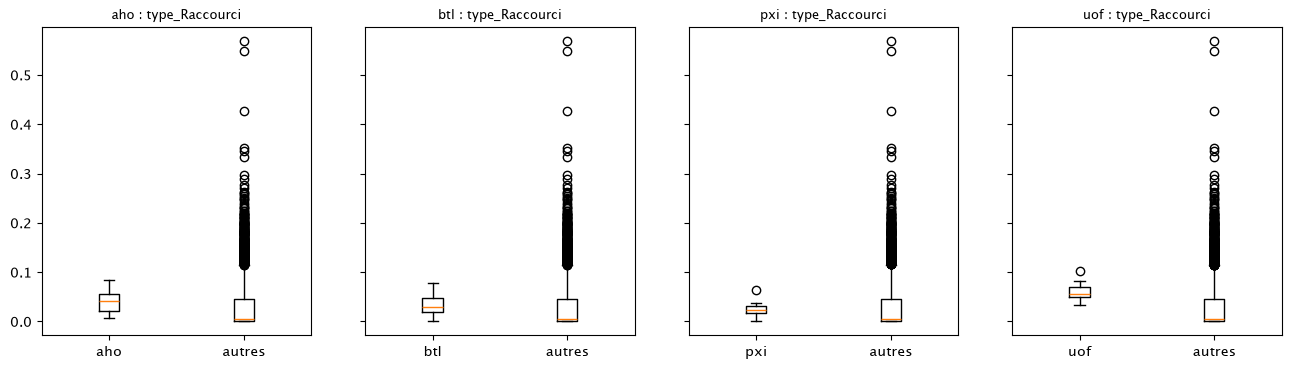

In [5]:
def boxplots(utils, feature="type_Raccourci"):
    """Distribution d'une feature pour quelques utilisateurs, contre toutes les autres sessions."""
    fig, axs = plt.subplots(1, len(utils), figsize=(16, 4), sharey=True)
    for ax, u in zip(axs, utils):
        code_u = classes.get_loc(u)
        ax.boxplot([X_train.loc[y == code_u, feature], X_train.loc[y != code_u, feature]])
        ax.set_xticks([1, 2], [u, "autres"])
        ax.set_title(f"{u} : {feature}", fontsize=9)
    plt.show()

boxplots(["aho", "btl", "pxi", "uof"])

**Observations**
- Pour un utilisateur, la valeur est très concentrée (`uof` ≈ 0,06, `pxi` ≈ 0,025) : chacun est régulier dans ses habitudes.
- Les utilisateurs se recouvrent encore en partie : c'est la combinaison des features qui discrimine.

## 4. Modèles

- Validation croisée stratifiée à **4 plis** (la classe la plus rare n'a que 4 sessions), **même découpage** pour tous les modèles.
- Métriques : accuracy et **F1 macro** (métrique du challenge : chaque utilisateur compte autant).
- Chaque cellule enregistre son modèle dans `modeles` : on pourra le choisir pour la soumission (section 6).

In [6]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)
modeles, resultats, predictions = {}, {}, {}

def evaluer(nom, modele):
    """Prédictions hors-pli sur le train, scores enregistrés dans `resultats`."""
    debut = time.time()
    preds = cross_val_predict(modele, X_train, y, cv=skf)
    modeles[nom], predictions[nom] = modele, preds
    resultats[nom] = {"accuracy": accuracy_score(y, preds), "F1 macro": f1_score(y, preds, average="macro"),
                      "durée (s)": time.time() - debut}
    print(f"{nom} : accuracy={resultats[nom]['accuracy']:.3f}  F1 macro={resultats[nom]['F1 macro']:.3f}  "
          f"({resultats[nom]['durée (s)']:.0f} s)")

### Référence : classe majoritaire
Toujours prédire l'utilisateur le plus fréquent : le score à battre.

In [7]:
from sklearn.dummy import DummyClassifier

evaluer("Classe majoritaire", DummyClassifier(strategy="most_frequent"))

Classe majoritaire : accuracy=0.023  F1 macro=0.000  (0 s)


### Régression logistique
- Modèle linéaire : on standardise les features (échelles très différentes).
- `C=1`.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

evaluer("Régression logistique", make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)))

Régression logistique : accuracy=0.867  F1 macro=0.858  (5 s)


### Random Forest
Forêt de 300 arbres ; pas besoin de standardiser.

In [9]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier

evaluer("Random Forest", RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))

Random Forest : accuracy=0.924  F1 macro=0.921  (11 s)


### ExtraTrees
Comme la Random Forest, mais les seuils de coupure sont tirés au hasard : des arbres plus variés.

In [10]:
evaluer("ExtraTrees", ExtraTreesClassifier(n_estimators=500, random_state=0, n_jobs=-1))

ExtraTrees : accuracy=0.931  F1 macro=0.930  (12 s)


### ExtraTrees réglé (`max_features=0.3`)
- Chaque coupure examine 30 % des features au lieu de √143 ≈ 12.

In [11]:
evaluer("ExtraTrees (max_features=0.3)",
        ExtraTreesClassifier(n_estimators=500, max_features=0.3, random_state=0, n_jobs=-1))

ExtraTrees (max_features=0.3) : accuracy=0.940  F1 macro=0.940  (12 s)


### LightGBM (baseline)
- Boosting : un arbre **par classe et par itération**. Avec 247 classes d'environ 10 sessions, il sur-apprend vite : réglage prudent (petites feuilles, petit pas, L2).

In [12]:
import lightgbm as lgb

evaluer("LightGBM", lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=7, min_child_samples=2,
                                       reg_lambda=5, colsample_bytree=0.7, n_jobs=-1, verbose=-1))

LightGBM : accuracy=0.766  F1 macro=0.714  (111 s)


### XGBoost
Même contrainte que LightGBM : arbres peu profonds (`max_depth=3`).

In [13]:
import xgboost as xgb

evaluer("XGBoost", xgb.XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, colsample_bytree=0.3,
                                     subsample=0.8, tree_method="hist", n_jobs=-1))

XGBoost : accuracy=0.859  F1 macro=0.849  (173 s)


## 5. Comparaison

In [14]:
tableau = pd.DataFrame(resultats).T.sort_values("F1 macro", ascending=False)
tableau.round({"accuracy": 3, "F1 macro": 3, "durée (s)": 0})

,accuracy,F1 macro,durée (s)
ExtraTrees (max_features=0.3),0.940,0.940,12.0
ExtraTrees,0.931,0.930,12.0
Random Forest,0.924,0.921,11.0
Régression logistique,0.867,0.858,5.0
XGBoost,0.859,0.849,173.0
LightGBM,0.766,0.714,111.0
Classe majoritaire,0.023,0.000,0.0


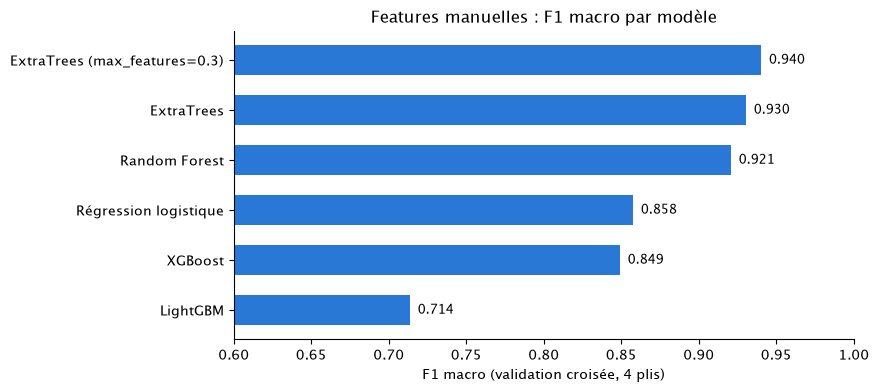

In [15]:
t = tableau.drop("Classe majoritaire").sort_values("F1 macro")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(t.index, t["F1 macro"], color="#2a78d6", height=0.6)
for i, v in enumerate(t["F1 macro"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.6, 1)
ax.set_xlabel("F1 macro (validation croisée, 4 plis)")
ax.set_title("Features manuelles : F1 macro par modèle")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Lecture**
- **Les forêts d'arbres dominent** sur ces features denses et hétérogènes ; l'ExtraTrees réglé est le meilleur.
- **La régression logistique est en retrait** : les features n'ont pas de relation linéaire simple avec l'utilisateur.
- **Le boosting sur-apprend** avec environ 13 sessions par classe, et c'est le plus lent.
- Les écarts de moins de 0,005 ne sont pas significatifs : réglages choisis sur cette même validation croisée.

### Où se trompe le meilleur modèle ?

In [16]:
meilleur = tableau.index[0]
erreurs = predictions[meilleur] != y
print(f"{meilleur} : {erreurs.sum()} erreurs sur {len(y)} sessions")
pd.Series(erreurs).groupby(pd.qcut(train["nb_actions"], 5), observed=True).mean().round(3).rename("taux d'erreur")

ExtraTrees (max_features=0.3) : 198 erreurs sur 3276 sessions


nb_actions
(12.999, 131.0]     0.146
(131.0, 250.0]      0.072
(250.0, 484.0]      0.041
(484.0, 997.0]      0.029
(997.0, 11977.0]    0.014
Name: taux d'erreur, dtype: float64

In [17]:
# utilisateurs les plus souvent mal reconnus, et avec qui ils sont confondus
confusions = pd.DataFrame({"vrai": classes[y], "prédit": classes[predictions[meilleur]]})[erreurs]
pires = confusions["vrai"].value_counts().head(5)
pd.DataFrame({"erreurs": pires, "sessions": pd.Series(classes[y]).value_counts()[pires.index],
              "confondu surtout avec": [confusions.loc[confusions["vrai"] == u, "prédit"].value_counts().head(2).index.tolist()
                                        for u in pires.index]})

,erreurs,sessions,confondu surtout avec
vrai,,,
flj,26,42,"[skm, slq]"
skm,11,75,"[slq, flj]"
azx,9,10,"[guh, sqb]"
urs,5,5,"[slq, flj]"
zok,5,11,"[sps, lra]"


- Les sessions courtes sont de loin les plus difficiles : peu d'actions, peu d'information.
- Les erreurs se concentrent sur quelques utilisateurs aux habitudes proches (`flj`, `skm`, `slq` : Chrome, sessions courtes).

### Variables les plus influentes
Importance moyenne (baisse d'impureté) dans l'ExtraTrees réglé, entraîné sur tout le train.

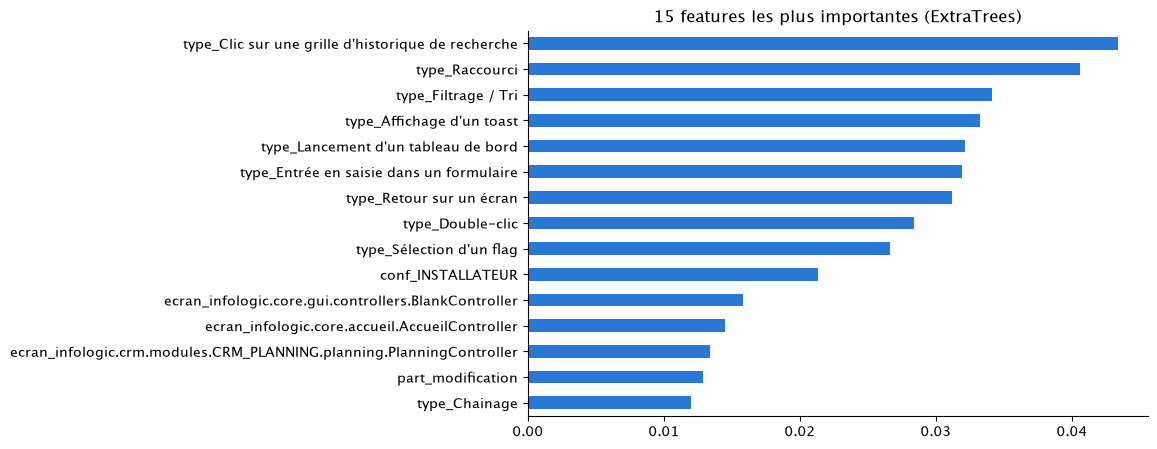

In [18]:
from sklearn.base import clone

et = clone(modeles["ExtraTrees (max_features=0.3)"]).fit(X_train, y)
importances = pd.Series(et.feature_importances_, X_train.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
importances.tail(15).plot.barh(ax=ax, color="#2a78d6")
ax.set_title("15 features les plus importantes (ExtraTrees)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

- Les plus importantes ne sont pas les statistiques de rythme, mais des **écrans, des configurations et des types d'action** : le signal est dans *ce que* font les utilisateurs.
- **Limite de l'approche** : 32 écrans et 20 configurations ne sont utilisés que par un seul utilisateur (de vraies signatures), et aucun n'est dans le top-K. D'où l'approche suivante, `3_tfidf_modeles.ipynb`, qui garde tout le vocabulaire.

## 6. Soumission

Choisir le modèle par son nom dans le tableau ci-dessus : il est réentraîné sur tout le train, puis prédit le test.

In [19]:
MODELE_SOUMISSION = "ExtraTrees (max_features=0.3)"   # un nom parmi : list(modeles)

assert MODELE_SOUMISSION in modeles, f"modèle inconnu, choisir parmi {list(modeles)}"
modele_final = clone(modeles[MODELE_SOUMISSION]).fit(X_train, y)
preds_test = modele_final.predict(X_test)

nom = unicodedata.normalize("NFKD", MODELE_SOUMISSION).encode("ascii", "ignore").decode().lower()
chemin = f"submissions/features_{re.sub(r'[^a-z0-9]+', '_', nom).strip('_')}.csv"
os.makedirs("submissions", exist_ok=True)
soumission = pd.DataFrame({"prediction": classes[preds_test]}, index=pd.RangeIndex(1, len(test) + 1, name="RowId"))
soumission.to_csv(chemin)
print(f"{MODELE_SOUMISSION} → {chemin}")
soumission.head()

ExtraTrees → submissions/features_extratrees.csv


,prediction
RowId,
1,hzx
2,prb
3,jmq
4,psg
5,cvw
